# Chapitre 3 - Exercices 3.1 à 3.6

Ce notebook traite les six premiers exercices du chapitre 3, consacrés aux moteurs
de stockage pour l'OLTP :

- **3.1** : dimensionner un index de hachage en mémoire à la Bitcask (calcul) ;
- **3.2** : la compaction, compromis entre espace disque et réécritures
  (démonstration et simulation) ;
- **3.3** : dimensionner les filtres de Bloom d'un arbre LSM, et répartir la mémoire
  entre niveaux (calcul et optimisation) ;
- **3.4** : choisir une stratégie de compaction selon la charge (mini-lab) ;
- **3.5** : hauteur d'un B-tree, cache des pages internes et E/S par lecture
  (calcul et vérification) ;
- **3.6** : trouver l'anomalie, une panne au milieu d'un éclatement de page
  (raisonnement et mini-lab).

In [1]:
import copy
import itertools
import math
import os
import random
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap

from ddia import storage as S
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
WORK = tempfile.mkdtemp(prefix="ddia_ex_")

## Exercice 3.1 : Dimensionner un index de hachage à la Bitcask

**Énoncé.** Un service compte les lectures de vidéos : la clé est l'URL de la vidéo
(60 octets en moyenne), la valeur un compteur de 8 octets. On a 50 millions de vidéos
et 20 000 mises à jour par seconde. Le moteur est un journal append-only avec un index
de hachage en mémoire. Un enregistrement sur disque comporte un en-tête de 12 octets
(somme de contrôle et deux longueurs), la clé et la valeur. Une entrée de la table de
hachage coûte la clé, 16 octets de localisation (segment, offset, taille) et environ 40
octets de surcoût de la structure.

1. Quelle mémoire faut-il pour l'index ? Tient-il sur une machine de 64 Go ?
2. De combien le journal grossit-il par jour sans compaction ?
3. On compacte dès que le disque contient deux fois plus d'octets que les données
   vivantes. Toutes les combien de temps ? Quel débit d'écriture la compaction
   ajoute-t-elle en moyenne ?
4. Au redémarrage, on reconstruit l'index en relisant les segments à 500 Mo/s. Combien
   de temps juste avant une compaction ? Et avec un fichier d'indices (*hint file*) qui
   contient seulement clé + localisation pour chaque clé vivante ?

**Rappels.** Index de hachage en mémoire sur un journal append-only, segments et
compaction, reprise après panne (section *Hash Indexes* ;
cours 1, sections 3 à 5).

**Solution.**

*1.* Par clé : $60 + 16 + 40 = 116$ octets ; pour $5 \times 10^7$ clés,
$5{,}8$ Go. L'index tient largement dans 64 Go : c'est le cas d'usage idéal de Bitcask
(peu de clés, beaucoup de mises à jour).

*2.* Un enregistrement occupe $12 + 60 + 8 = 80$ octets. Par jour :
$2 \times 10^4 \times 86\,400 \times 80 \approx 138$ Go, soit environ 50 To par an,
alors que les données vivantes ne font que $5 \times 10^7 \times 80 = 4$ Go.

*3.* Le disque passe de 4 Go (juste après compaction) à 8 Go : il faut écrire 4 Go
d'enregistrements, soit $4 \times 10^9 / (2 \times 10^4 \times 80) = 2\,500$ s, environ
42 minutes. À chaque compaction, on réécrit les 4 Go vivants : en moyenne
$4\,\text{Go} / 2\,500\,\text{s} = 1{,}6$ Mo/s, autant que le débit applicatif
($2 \times 10^4 \times 80 = 1{,}6$ Mo/s). L'amplification d'écriture vaut donc 2
(exercice suivant).

*4.* Juste avant compaction, 8 Go à relire : 16 s. Le fichier d'indices contient
$5 \times 10^7 \times (60 + 16) = 3{,}8$ Go : 7,6 s, et surtout, il n'y a plus à
décoder les valeurs ni à écarter les versions obsolètes. Avec des valeurs plus grosses
(des documents de quelques Ko), le gain serait bien plus net : le fichier d'indices ne
dépend que des clés.

In [2]:
cles, k, loc, surcout, val, hdr = 5e7, 60, 16, 40, 8, 12
debit = 2e4
rec = hdr + k + val
vivant = cles * rec
res = pd.Series({
    "RAM de l'index (Go)": cles * (k + loc + surcout) / 1e9,
    "croissance par jour sans compaction (Go)": debit * 86_400 * rec / 1e9,
    "données vivantes (Go)": vivant / 1e9,
    "intervalle entre compactions (min)": vivant / (debit * rec) / 60,
    "débit moyen de compaction (Mo/s)": vivant / (vivant / (debit * rec)) / 1e6,
    "reprise par relecture du journal (s)": 2 * vivant / 500e6,
    "reprise par fichier d'indices (s)": cles * (k + loc) / 500e6,
}).round(2).to_frame("valeur")
res

,valeur
RAM de l'index (Go),5.80
croissance par jour sans compaction (Go),138.24
données vivantes (Go),4.00
intervalle entre compactions (min),41.67
débit moyen de compaction (Mo/s),1.60
reprise par relecture du journal (s),16.00
reprise par fichier d'indices (s),7.60


**Vérification expérimentale** à petite échelle : 20 000 clés, une compaction quand le
disque atteint deux fois les données vivantes, et la reconstruction de l'index après
fermeture. On compare le volume relu à celui d'un fichier d'indices.

In [3]:
st = S.HashIndexStore(os.path.join(WORK, "ex1"), segment_bytes=64 * 1024)
n_cles = 20_000
for i in range(n_cles):
    st.put(f"https://video.example/{i:07d}", "00000000")
rng = np.random.default_rng(0)
compactions = 0
vivant_ex1 = st.live_bytes()  # constant : clés et valeurs de taille fixe
for n in range(120_000):
    i = int(rng.integers(n_cles))
    st.put(f"https://video.example/{i:07d}", f"{n:08d}")
    if n % 200 == 0 and st.disk_bytes() >= 2 * vivant_ex1:
        st.compact()
        compactions += 1
st.close()
st2 = S.HashIndexStore.open(os.path.join(WORK, "ex1"), segment_bytes=64 * 1024)
hint = sum(len(kk) + 16 for kk in st2.index)
pd.Series({"compactions": compactions, "octets relus à la reprise": st2.bytes_scanned,
           "taille d'un fichier d'indices": hint, "rapport": st2.bytes_scanned / hint,
           "amplification d'écriture": (st.user_bytes + st.compaction_bytes) / st.user_bytes}).round(2).to_frame("mesure")

,mesure
compactions,5.000e+00
octets relus à la reprise,1.961e+06
taille d'un fichier d'indices,9.000e+05
rapport,2.180e+00
amplification d'écriture,1.680e+00


La simulation donne une amplification d'écriture un peu inférieure à 2 (environ 1,7) :
le segment actif n'est jamais compacté, et ses versions obsolètes échappent donc à la
réécriture. À la reprise, le journal à relire est environ deux fois plus gros qu'un
fichier d'indices, comme prévu juste avant une compaction.

> **À retenir.** Un index de hachage en mémoire coûte (clé + localisation + surcoût) par
> clé : parfait pour des millions de clés, intenable pour des milliards. Sans
> compaction le journal croît sans limite ; avec, on paie des réécritures. Les fichiers
> d'indices accélèrent la reprise.

## Exercice 3.2 : Compaction, espace disque et réécritures

**Énoncé.** Un moteur à journal compacte dès que l'espace disque atteint $\alpha$ fois
le volume des données vivantes $L$ (avec $\alpha > 1$), et la compaction ramène le disque
à $L$. Les mises à jour écrasent des clés existantes (le volume vivant reste constant).

1. Montrer que l'amplification d'écriture (octets écrits au total / octets écrits par
   l'application) vaut $\mathrm{WA} = \dfrac{\alpha}{\alpha - 1}$ et que
   l'amplification d'espace maximale vaut $\alpha$.
2. Tracer le compromis et commenter les cas $\alpha = 1{,}1$ et $\alpha = 4$.
3. Vérifier par simulation avec `S.HashIndexStore`.

**Rappels.** Segments, fusion et compaction ; amplification d'écriture (cours 1,
section 4 ; section *Comparing B-Trees and LSM-Trees*).

**Solution.**

*1.* Considérons un cycle entre deux compactions. Le disque passe de $L$ à $\alpha L$ :
l'application a écrit $(\alpha - 1)L$ octets. La compaction réécrit alors les $L$
octets vivants. Sur un cycle, le total écrit vaut $(\alpha - 1)L + L = \alpha L$, d'où
$$\mathrm{WA} = \frac{\alpha L}{(\alpha - 1)L} = \frac{\alpha}{\alpha - 1} = 1 + \frac{1}{\alpha - 1}.$$
L'espace occupé oscille entre $L$ et $\alpha L$ : l'amplification d'espace maximale est
$\alpha$ (en moyenne $(1 + \alpha)/2$). $\blacksquare$

*2.* Le produit des deux surcoûts est fixé : on ne peut pas avoir à la fois peu d'espace
gaspillé et peu de réécritures. Avec $\alpha = 1{,}1$ (10 % d'espace en plus), chaque
octet est écrit 11 fois ; avec $\alpha = 4$, on écrit seulement 1,33 fois mais on occupe
jusqu'à 4 fois l'espace utile. C'est, en miniature, la « conjecture RUM » citée par le
livre : on ne peut pas optimiser à la fois lectures, écritures et espace.

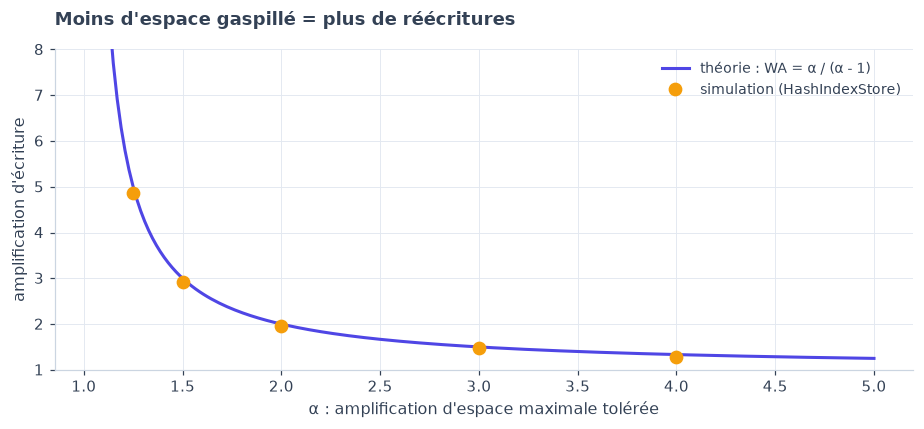

,alpha,WA_mesuree,WA_theorie,espace_max
0,1.25,4.858,5.000,1.25
1,1.50,2.928,3.000,1.50
2,2.00,1.965,2.000,2.00
3,3.00,1.478,1.500,3.00
4,4.00,1.291,1.333,4.00


In [4]:
alphas = [1.25, 1.5, 2.0, 3.0, 4.0]
mesures = []
for a in alphas:
    st = S.HashIndexStore(os.path.join(WORK, f"ex2_{a}"), segment_bytes=16 * 1024)
    for i in range(3000):
        st.put(S.kv_key(i), S.kv_value(i, size=50))
    st.user_bytes, st.compaction_bytes = 0, 0
    rng = np.random.default_rng(1)
    pic = 0
    L = st.live_bytes()  # constant : on ne fait qu'écraser des clés existantes
    disque = st.disk_bytes()
    for n in range(60_000):
        i = int(rng.integers(3000))
        st.put(S.kv_key(i), S.kv_value(i, n, size=50))
        disque += S.record_size(S.kv_key(i), S.kv_value(i, n, size=50))
        if disque >= a * L:
            pic = max(pic, disque / L)
            st.compact()
            disque = st.disk_bytes()
    mesures.append(dict(alpha=a, WA_mesuree=(st.user_bytes + st.compaction_bytes) / st.user_bytes,
                        WA_theorie=a / (a - 1), espace_max=pic))
    st.close()
mes = pd.DataFrame(mesures)
fig, ax = plt.subplots(figsize=(8.5, 4))
aa = np.linspace(1.05, 5, 200)
ax.plot(aa, aa / (aa - 1), color=INDIGO, label="théorie : WA = α / (α - 1)")
ax.plot(mes.alpha, mes.WA_mesuree, "o", color=AMBER, ms=8, label="simulation (HashIndexStore)")
ax.set_ylim(1, 8)
ax.set_xlabel("α : amplification d'espace maximale tolérée"); ax.set_ylabel("amplification d'écriture")
ax.set_title("Moins d'espace gaspillé = plus de réécritures")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()
mes

Les mesures suivent la courbe, un peu en dessous : la compaction ne touche pas au
segment actif, dont les versions obsolètes échappent à la réécriture.

> **À retenir.** Compacter dès que l'espace atteint $\alpha$ fois les données vivantes
> coûte une amplification d'écriture $\alpha/(\alpha-1)$ : espace et réécritures
> s'échangent l'un contre l'autre.